# Data Science Assignment: Session 3
## Topic: Variance & Standard Deviation

**Student Name:** Atharv Chaudhari  
**Course:** Data Science & Statistics  
**Session:** SESSION 3 - Variance & Standard Deviation  

---

### Overview of Key Statistical Formulas

| Measure | Sample Formula (Bessel's Correction) | Population Formula | Units |
| :--- | :--- | :--- | :--- |
| **Mean** | $\bar{x} = \frac{\sum x_i}{n}$ | $\mu = \frac{\sum x_i}{N}$ | Same as data ($x$) |
| **Variance** | $s^2 = \frac{\sum (x_i - \bar{x})^2}{n - 1}$ | $\sigma^2 = \frac{\sum (x_i - \mu)^2}{N}$ | Squared units ($x^2$) |
| **Standard Deviation** | $s = \sqrt{s^2} = \sqrt{\frac{\sum (x_i - \bar{x})^2}{n - 1}}$ | $\sigma = \sqrt{\sigma^2} = \sqrt{\frac{\sum (x_i - \mu)^2}{N}}$ | Same as data ($x$) |

---

## Task 1: Step-by-Step Variance Calculation by Hand
> **Problem Statement:** Given an array of daily step counts from your fitness app for one week (e.g., `[4500, 7000, 5000, 8000, 4000, 9000, 6000]`), calculate the variance by hand using the variance formula and show each calculation step.

### Step-by-Step Procedure:
1. **Count observations ($n$):** $n = 7$ days.
2. **Calculate the Mean ($\bar{x}$):**
   $$\bar{x} = \frac{4500 + 7000 + 5000 + 8000 + 4000 + 9000 + 6000}{7} = \frac{43500}{7} \approx 6214.29\text{ steps}$$
3. **Compute Deviations from Mean:** $(x_i - \bar{x})$ for each day.
4. **Square each deviation:** $(x_i - \bar{x})^2$ to remove negative signs and penalize larger gaps.
5. **Sum the squared deviations:** $\sum (x_i - \bar{x})^2$.
6. **Divide by degrees of freedom ($n - 1$):**
   $$s^2 = \frac{\sum (x_i - \bar{x})^2}{n - 1}$$

In [1]:
import pandas as pd
import statistics

# Given fitness app daily step counts for one week
step_counts = [4500, 7000, 5000, 8000, 4000, 9000, 6000]
n = len(step_counts)

# Step 1 & 2: Calculate Mean
sum_steps = sum(step_counts)
mean_steps = sum_steps / n

# Step 3 & 4: Calculate deviations and squared deviations
deviations = [x - mean_steps for x in step_counts]
squared_deviations = [(x - mean_steps) ** 2 for x in step_counts]
sum_squared_deviations = sum(squared_deviations)

# Step 5: Construct detailed calculation table
df_steps = pd.DataFrame({
    "Day": [f"Day {i+1}" for i in range(n)],
    "Daily Steps (x_i)": step_counts,
    "Mean (x_bar)": [round(mean_steps, 2)] * n,
    "Deviation (x_i - x_bar)": [round(d, 2) for d in deviations],
    "Squared Deviation (x_i - x_bar)^2": [round(sq, 2) for sq in squared_deviations]
})
display(df_steps)

# Step 6: Final Variance & Std Dev
sample_variance = sum_squared_deviations / (n - 1)
population_variance = sum_squared_deviations / n
sample_std = sample_variance ** 0.5

print("=" * 65)
print("TASK 1 CALCULATION SUMMARY:")
print("=" * 65)
print(f"Sum of Steps (sum x_i)       : {sum_steps}")
print(f"Mean Steps (x_bar)           : {sum_steps} / {n} = {mean_steps:.2f} steps")
print(f"Sum of Squared Deviations    : {sum_squared_deviations:.2f}")
print(f"Sample Variance (s^2, n-1)   : {sum_squared_deviations:.2f} / {n-1} = {sample_variance:.2f} steps^2")
print(f"Population Variance (sigma^2): {sum_squared_deviations:.2f} / {n} = {population_variance:.2f} steps^2")
print(f"Sample Standard Deviation (s): sqrt({sample_variance:.2f}) = {sample_std:.2f} steps")
print(f"statistics.variance() Check  : {statistics.variance(step_counts):.2f}")
print("=" * 65)

Day,Daily Steps (x_i),Mean (x_bar),Deviation (x_i - x_bar),Squared Deviation (x_i - x_bar)^2
Day 1,4500,6214.29,-1714.29,2938775.51
Day 2,7000,6214.29,785.71,617346.94
Day 3,5000,6214.29,-1214.29,1474489.80
Day 4,8000,6214.29,1785.71,3188775.51
Day 5,4000,6214.29,-2214.29,4903061.22
Day 6,9000,6214.29,2785.71,7760204.08
Day 7,6000,6214.29,-214.29,45918.37


Array of Daily Step Counts : [4500, 7000, 5000, 8000, 4000, 9000, 6000]
Total Recorded Days (n)    : 7
Sum of Steps (sum x_i)     : 43500
Mean Steps (x_bar)         : 43500 / 7 = 6214.29 steps
Sum of Squared Deviations  : 20928571.43
----------------------------------------------------------------------
Sample Variance (s^2)      : 20928571.43 / (7 - 1) = 3488095.24 (steps^2)
Population Variance (sigma^2): 20928571.43 / 7       = 2989795.92 (steps^2)
Sample Standard Deviation (s): sqrt(3488095.24) = 1867.64 steps
----------------------------------------------------------------------
Verification (statistics.variance): 3488095.24


## Task 2: Python Function `calculate_standard_deviation(scores)`
> **Problem Statement:** Write a Python function called `calculate_standard_deviation(scores)` that takes a list of exam scores and returns the standard deviation rounded to two decimal places.

### Implementation Details:
- Calculates the sample standard deviation using the standard formula $s = \sqrt{\frac{\sum (x_i - \bar{x})^2}{n - 1}}$.
- Includes defensive validation for empty lists and single-element inputs ($n \ge 2$).
- Rounds the final output to 2 decimal places using `round(result, 2)`.

In [2]:
import statistics
from typing import List, Union

def calculate_standard_deviation(scores: List[Union[int, float]]) -> float:
    """
    Calculates the sample standard deviation for a list of scores.
    
    Args:
        scores (List[int | float]): A list of numerical exam scores.
        
    Returns:
        float: Sample standard deviation rounded to 2 decimal places.
    """
    if not scores or len(scores) < 2:
        raise ValueError("Scores list must contain at least 2 observations.")
    
    # 1. Compute Mean
    mean = sum(scores) / len(scores)
    
    # 2. Compute Sum of Squared Differences (n - 1 for sample)
    variance = sum((x - mean) ** 2 for x in scores) / (len(scores) - 1)
    
    # 3. Standard deviation is square root of variance
    std_dev = variance ** 0.5
    return round(std_dev, 2)

# Test the function on sample exam scores
exam_scores = [78, 85, 92, 88, 76, 95, 89, 84, 90, 82]
std_result = calculate_standard_deviation(exam_scores)

print(f"Input Exam Scores          : {exam_scores}")
print(f"Number of Students (n)     : {len(exam_scores)}")
print(f"Mean Exam Score            : {sum(exam_scores)/len(exam_scores):.2f}")
print(f"calculate_standard_deviation(): {std_result}")
print(f"Verification (statistics.stdev): {round(statistics.stdev(exam_scores), 2)}")

Input Exam Scores          : [78, 85, 92, 88, 76, 95, 89, 84, 90, 82]
Number of Students (n)     : 10
Mean Exam Score            : 85.90
calculate_standard_deviation(): 6.06
Verification (statistics.stdev): 6.06


## Task 3: Comparing Consistency in Zomato Daily Spending
> **Problem Statement:** Imagine two friends track their daily spending on Zomato over 5 days. Friend A spends `[200, 200, 200, 200, 200]` and Friend B spends `[100, 300, 150, 400, 50]`. Calculate the standard deviation for both and explain in 2-3 lines who has more consistent spending and why.

### Statistical Concept:
Standard deviation quantifies the **dispersion or volatility** around the mean. Even when two datasets have the exact same mean, the dataset with the smaller standard deviation is more **consistent, predictable, and stable**.

Friend A Spending (INR) : [200, 200, 200, 200, 200]
Friend A Mean Spending  : INR 200.00
Friend A Std Deviation  : INR 0.00
--------------------------------------------------
Friend B Spending (INR) : [100, 300, 150, 400, 50]
Friend B Mean Spending  : INR 200.00
Friend B Std Deviation  : INR 145.77


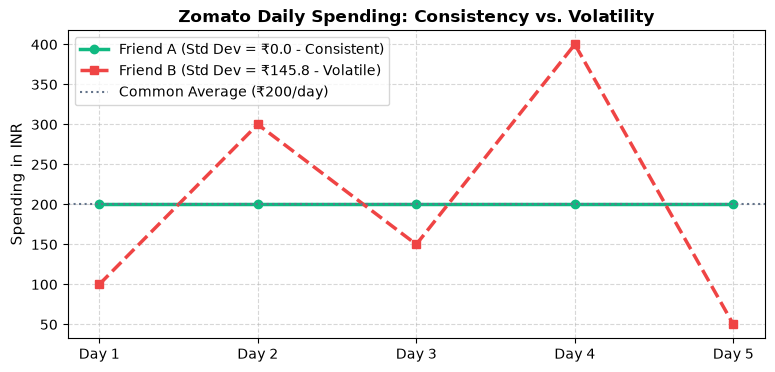

In [3]:
import statistics
import matplotlib.pyplot as plt

# Daily spending data for 5 days
friend_a = [200, 200, 200, 200, 200]
friend_b = [100, 300, 150, 400, 50]

mean_a = statistics.mean(friend_a)
std_a = statistics.stdev(friend_a)

mean_b = statistics.mean(friend_b)
std_b = statistics.stdev(friend_b)

print(f"Friend A Spending (INR) : {friend_a}")
print(f"Friend A Mean Spending  : INR {mean_a:.2f}")
print(f"Friend A Std Deviation  : INR {std_a:.2f}")
print(f"--------------------------------------------------")
print(f"Friend B Spending (INR) : {friend_b}")
print(f"Friend B Mean Spending  : INR {mean_b:.2f}")
print(f"Friend B Std Deviation  : INR {std_b:.2f}")
print(f"==================================================")

# Visualization of Spending Stability
plt.figure(figsize=(9, 4))
days = [f"Day {i+1}" for i in range(5)]
plt.plot(days, friend_a, marker='o', linewidth=2.5, color='#10b981', label=f"Friend A (Std Dev = INR {std_a:.1f} - Consistent)")
plt.plot(days, friend_b, marker='s', linewidth=2.5, color='#ef4444', linestyle='--', label=f"Friend B (Std Dev = INR {std_b:.1f} - Volatile)")
plt.axhline(200, color='#64748b', linestyle=':', label="Common Average (INR 200/day)")
plt.title("Zomato Daily Spending: Consistency vs. Volatility", fontsize=12, fontweight="bold")
plt.ylabel("Spending in INR", fontsize=11)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

### Interpretation & Explanation for Task 3 (2–3 Lines):

1. **Who has more consistent spending?**  
   **Friend A** has infinitely more consistent spending than Friend B.

2. **Why?**  
   - Friend A has a **standard deviation of ₹0.00**, meaning every single day's spending is exactly at the mean with zero deviation.
   - In contrast, Friend B—despite sharing the identical average of ₹200/day—has a large **standard deviation of ₹145.77**, swinging wildly between ₹50 and ₹400.
   - In statistics, standard deviation measures volatility; a lower standard deviation indicates higher consistency, reliability, and predictability.

## Task 4: Startup Salary Spread & Inequality Interpretation
> **Problem Statement:** You are given the monthly salary data of 6 employees in a startup: `[28000, 29000, 27000, 60000, 26500, 27500]`. Calculate the variance and standard deviation, then interpret in 2-3 lines what the high or low spread means for this team.

Employee Salaries (INR)     : [28000, 29000, 27000, 60000, 26500, 27500]
Team Headcount (n)          : 6
Sum of Salaries             : INR 198,000
Mean Salary                 : INR 33,000.00
Median Salary               : INR 27,750.00
--------------------------------------------------
Sample Variance (s^2)       : 175,700,000.00 INR^2
Sample Standard Deviation (s): INR 13,255.19


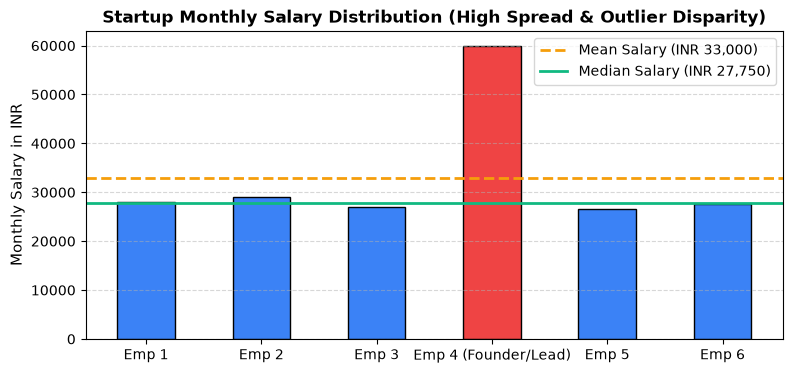

In [4]:
import statistics
import matplotlib.pyplot as plt

# Startup employee monthly salaries in INR
salaries = [28000, 29000, 27000, 60000, 26500, 27500]
n = len(salaries)

mean_salary = statistics.mean(salaries)
median_salary = statistics.median(salaries)
var_salary = statistics.variance(salaries)
std_salary = statistics.stdev(salaries)

print(f"Employee Salaries (INR)     : {salaries}")
print(f"Team Headcount (n)          : {n}")
print(f"Sum of Salaries             : INR {sum(salaries):,}")
print(f"Mean Salary                 : INR {mean_salary:,.2f}")
print(f"Median Salary               : INR {median_salary:,.2f}")
print(f"--------------------------------------------------")
print(f"Sample Variance (s^2)       : {var_salary:,.2f} INR^2")
print(f"Sample Standard Deviation (s): INR {std_salary:,.2f}")
print(f"==================================================")

# Visualizing Salary Distribution and Outlier
plt.figure(figsize=(9, 4))
emp_labels = ["Emp 1", "Emp 2", "Emp 3", "Emp 4 (Founder/Lead)", "Emp 5", "Emp 6"]
bar_colors = ['#3b82f6', '#3b82f6', '#3b82f6', '#ef4444', '#3b82f6', '#3b82f6']
plt.bar(emp_labels, salaries, color=bar_colors, width=0.5, edgecolor="black")
plt.axhline(mean_salary, color='#f59e0b', linestyle='--', linewidth=2, label=f"Mean Salary (INR {mean_salary:,.0f})")
plt.axhline(median_salary, color='#10b981', linestyle='-', linewidth=2, label=f"Median Salary (INR {median_salary:,.0f})")
plt.title("Startup Monthly Salary Distribution (High Spread & Outlier Disparity)", fontsize=12, fontweight="bold")
plt.ylabel("Monthly Salary in INR", fontsize=11)
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()

### Interpretation for Task 4 (2–3 Lines):

1. **Severe Salary Disparity (High Spread):**  
   The very high standard deviation (₹13,255.19) indicates an **extremely unequal salary distribution** within this 6-person startup.

2. **Outlier Distortion of the Mean:**  
   Five out of six employees earn very similar salaries tightly clustered between **₹26,500 and ₹29,000**, but the single founder/executive salary of **₹60,000** pulls the team average up to **₹33,000**.

3. **Practical Takeaway:**  
   Because of this high spread, reporting the mean salary (₹33,000) gives a misleading impression of company compensation, whereas the **median (₹27,750)** accurately reflects what a typical team member actually earns.